<a href="https://colab.research.google.com/github/MARIAKVELASH/analysis_everpeak/blob/main/everpeak_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Introducción

Como analista de datos, tu objetivo es **evaluar cómo la movilidad urbana se relaciona con la productividad económica en las principales ciudades latinoamericanas**.
Para ello trabajarás con datos reales de TomTom Traffic Index y OECD Cities, que deberás limpiar, combinar y analizar para identificar en qué ciudades conviene invertir en infraestructura de transporte.

## 🧩 Paso 1: Cargar y explorar

Antes de limpiar o combinar los datos, es necesario **familiarizarte con la estructura de ambos datasets**.
En esta etapa, validarás que los archivos se carguen correctamente, conocerás sus columnas y tipos de datos, y detectarás posibles inconsistencias.

### 1.1 Carga de datos y vista rápida

**🎯Objetivo:**
Importar las librerías necesarias, cargar los archivos CSV en DataFrames y realizar una revisión preliminar para entender su contenido.

**Instrucciones:**
- Importa las librerías `pandas`, `numpy`, `seaborn` y `matplotlib.pyplot`.
- Carga los archivos usando `pd.read_csv()`:
  - `'/datasets/tomtom_traffic.csv'`
  - `/datasets/oecd_city_economy.csv` `.
- Guarda los DataFrames en las variables `traffic` y `eco`.
- Muestra las primeras 5 filas de cada DataFrame.


In [1]:
# importar librerías
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [ ]:
# cargar archivos
traffic = pd.read_csv('/datasets/tomtom_traffic.csv')
eco = pd.read_csv('/datasets/oecd_city_economy.csv')

FileNotFoundError: [Errno 2] No such file or directory: '/datasets/tomtom_traffic.csv'

In [ ]:
# mostrar las primeras 5 filas de traffic
print(traffic.head(5))

NameError: name 'traffic' is not defined

In [ ]:
# mostrar las primeras 5 filas de eco
print(eco.head(5))

NameError: name 'eco' is not defined

**Tip:** Si no usas `print()` la tabla se vera mejor.

In [ ]:
# Nuevo análisis: detectar outliers con IQR
Q1 = df['order_value'].quantile(0.25)
Q3 = df['order_value'].quantile(0.75)
IQR = Q3 - Q1
upper = Q3 + 1.5*IQR
df['outlier_flag'] = df['order_value'] > upper


---

## 🧩Paso 2: Explorar, limpiar y preparar los datos

Antes de combinar los datasets, inspecciona su estructura, tipos de datos, columnas y valores faltantes.
Anota las columnas que necesiten limpieza y luego estandariza los nombres de columnas.

### 2.1 Explorar la estructura y tipos de datos

**🎯Objetivo:**
Identificar columnas con tipos incorrectos, distribución y nulos, anotar las columnas que requieren conversión.

**Instrucciones:**

- Usa `.info()` para conocer la estructura de ambos DataFrames.
- Muestra los primeros 3 renglones de cada DF.
- Identifica si los detalles de cada DF estan bien o si requieren correcciones y escribe tus conclusiones en el bloque Markdown.
  - ¿Hay columnas que requieren conversión?¿ Cuáles son? ¿Que tipo de dato ienen y cuál deberían de tener?
  - ¿Hay datos ausentes en alguna columna?


In [ ]:
# Examinar la estructura de traffic
print(traffic.head(3).info())


NameError: name 'traffic' is not defined

este dataframe es un ensayo de datos para colocar commmin en github es importante buscar soluciones y leer los datos y procesos adicionales de el dataframe

#
df.isnull().sum()

En la estructura del DF traffic, se observa que:
- Las columnas `UpdateTimeUTC` y `UpdateTimeUTC` son de tipo datetimed pero estan en objet
- hay tres non-null por columna

In [ ]:
# Examinar la estructura de eco
print(eco.head(3).info())

NameError: name 'eco' is not defined

En la estructura del DF eco, se observa que:
- Las columnas `City GDP/capita`, `Unemployment %`, son numericas pero estan en object
- hay tres non-null por columna

### 2.2 Renombrar columnas

**🎯Objetivo:**
Estandarizar los nombres de columnas para evitar errores y facilitar la unión de los datasets.

**Instrucciones:**

- Cambia los nombres de las columnas para que tengan el formato `snake_case`.
    - `Country` → `country`
    - `UpdateTimeUTC` → `update_time_utc`
- Verifica que los cambios se hayan aplicado correctamente usando `.columns`.


In [ ]:
# Estandarizar los nombres de las columnas de traffic
#tu código aquí

traffic = traffic.rename(columns={'Country': 'country',
'UpdateTimeUTC': 'update_time_utc', 'UpdateTimeUTCWeekAgo' : 'update_time_utc_week_ago',
                        'City': 'city','JamsDelay': 'jams_delay',\
        'TrafficIndexLive' : 'traffic_index_live','JamsLengthInKms': 'jams_length_kms', 'JamsCount': 'jams_count', 'MinsDelay': 'mins_delay',\
    'TravelTimeLivePer10KmsMins': 'travel_time_live_per_10kms_mins','TravelTimeHistoricPer10KmsMins': 'travel_time_hist_per_10kms_mins'})

# verificar cambios
print(traffic.columns)


NameError: name 'traffic' is not defined

In [ ]:
# Estandarizar los nombres de las columnas de eco
eco = eco.rename(columns = {
    'Country' : 'country',
'UpdateTimeUTC' : 'update_time_utc',
   'City GDP/capita' :'city_gdp_capita',
    'Unemployment %' : 'unemployment_pct',
    'Population (M)' : 'population_m',
    'Year' : 'year',
    'City' : 'city', 'PM2.5 (μg/m³)': 'pm25'
})

# verificar cambios
print(eco.columns)

NameError: name 'eco' is not defined


### 2.3 Corregir formatos numéricos y de fecha

**🎯Objetivo:**
Asegurar que las columnas de fechas y valores numéricos estén en formatos correctos para permitir análisis, cálculos y comparaciones precisas.

**Instrucciones:**

- Convierte las columnas de fecha de `traffic` a formato `datetime`. Haz el cambio a prueba de errores.
- En el dataset `eco`, limpia los valores numéricos:
    - En `city_gdp_capita`: elimina separadores de miles (`.`) y reemplaza las comas (`','`) por puntos (`'.'`) antes de convertir a tipo `float`.
    - En `unemployment_pct`: elimina el símbolo de porcentaje (`%`) y reemplaza las comas (`','`) por puntos (`'.'`) antes de convertir a tipo `float`.
    - En `population_m`: reemplaza las comas (`','`) por puntos (`'.'`) antes de convertir a tipo `float`.
- Finalmente, crea una nueva columna llamada `population` multiplicando `population_m` por 1,000,000 para obtener la población total.


<details>
<summary>Haz clic para ver la pista</summary>
para eliminar símbolos, puedes reemplazarlos por un texto vacío.

In [ ]:
# Convertir las columnas de traffic a tipo fecha con pd.to_datetime()

traffic['update_time_utc'] = pd.to_datetime(traffic['update_time_utc'],errors= 'coerce')
traffic['update_time_utc_week_ago'] = pd.to_datetime(traffic['update_time_utc_week_ago'],errors= 'coerce')

# verificar el cambio
traffic.info()


NameError: name 'traffic' is not defined

In [ ]:
# Limpia separadores y convierte columnas numéricas en eco
eco['city_gdp_capita'] = eco['city_gdp_capita'].astype(str).str.replace('.', '').str.replace(',', '.').astype(float)
eco['unemployment_pct'] = eco['unemployment_pct'].astype(str).str.replace('.', '').str.replace(',', '.').str.replace('%', '').astype(float)
eco['population_m'] = eco['population_m'].astype(str).str.replace('.', '').str.replace(',', '.').astype(float)
eco['pm25'] = eco['pm25'].astype(str).str.replace(',', '.').astype(float)
# Calcula la población total en unidades absolutas (Multiplica * 1000000)
eco['population'] = eco['population_m']*1000000
eco['unemployment_pct'] = eco['unemployment_pct'].astype(float)/100

# verificar el cambio
eco.info()
eco.head(3)

NameError: name 'eco' is not defined


---

## 🧩Paso 3: Extraer año y filtrar

Extraer el año permite filtrar la información y trabajar solo con el período más reciente y relevante.

### 3.1 Extraer columna año y filtrar 2024

**🎯Objetivo**
Identificar el año de cada registro y mantener solo los registros del 2024.

**Intrucciones**

- Como el DataFrame `traffic` no tiene una columna de año, utiliza el atributo `.dt.year` sobre su columna de fecha para crear una nueva columna llamada `year`.
- Filtra las filas donde el año sea **2024**.
- Utiliza `.copy()` para crear dos nuevos DataFrames (`traffic_2024` y `eco_2024`) para evitar modificar el dataset original.

In [ ]:
# Extraer el año de las fechas en update_time_utc

traffic['year'] = traffic['update_time_utc'].dt.year

# Verificar cambio
traffic.head()


In [ ]:
# Filtra los registros del año 2024
traffic_2024 = traffic.copy()
eco_2024 = eco.copy()
traffic_2024 = traffic_2024[traffic_2024['year'] == 2024]
eco_2024 = eco_2024[eco_2024['year'] == 2024]

# Revisar dataframes nuevos
display(traffic_2024.head())
display(eco_2024.head())


NameError: name 'traffic' is not defined

<div class="alert alert-block alert-success">
<b>Comentario de la revisora Iteración #1</b> <a class="tocSkip"></a>

Excelente trabajo en este caso, pudiste filtrar de forma adecuada los datos para el año 2024 haciendo uso de los métodos necesarios para ello.


---

## 🧩Paso 4: Analizar y resumir datos de movilidad

Como el dataset de tráfico contiene **múltiples registros por ciudad**. En esta parte, calcularás los promedios anuales por ciudad para simplificar el análisis y obtener una visión más clara de las tendencias generales.

### 4.1 Calcular promedios de tráfico por ciudad

**🎯Objetivo:**
Obtener una vista consolidada del tráfico promedio por ciudad y año, para analizar patrones generales sin depender de datos diarios.

**Instrucciones**

- Agrupa los datos por `city`, `country` y `year`.
- Calcula el promedio **solo de las métricas de tráfico más relevantes**: como `jams_delay`, `traffic_index_live`, `jams_length_kms`, `jams_count`, `mins_delay`, y tiempos de viaje (`travel_time_live_per_10kms_mins` y `travel_time_hist_per_10kms_mins`).
- Guarda el resultado como `traffic_city_year_2024`, mantén las columnas como variables (no índices).


<details>
<summary>Haz clic para ver la pista</summary>
Usa ".agg()" para aplicar funciones de promedio. Al final, reinicia el índice para mantener las columnas de la agrupación como variables (no índices).

In [ ]:
# Calcular los  promedios de trafico por ciudad, país y año
traffic_city_year_2024 = traffic_2024.groupby(['city', 'country', 'year'])\
    [['jams_delay','traffic_index_live', 'jams_length_kms', 'jams_count', 'mins_delay', 'travel_time_live_per_10kms_mins',\
      'travel_time_hist_per_10kms_mins']].mean().reset_index()
# Mostrar

traffic_city_year_2024.head()



NameError: name 'traffic_2024' is not defined

In [ ]:
print(list(traffic_2024.columns))

### 🧠 **Momento de reflexión**

¡Excelente trabajo hasta aquí!

Ahora que ya tienes los promedios anuales por ciudad, es momento de **observarlos** con atención.

Piensa:

- ¿Cuál crees que tiene el mayor tiempo promedio de tráfico?
- ¿Será una ciudad de **Europa**, de **Latinoamérica** o de **otra región** del mundo?

Para descubrirlo, ejecuta esta línea de código:

`traffic_city_year_2024.sort_values(["jams_delay"], ascending=False)`


🔍 Observa qué ciudad aparece en los primeros lugares.

¿Te sorprenden los resultados? , ¿Coinciden con lo que imaginabas?

In [ ]:
traffic_city_year_2024.sort_values(["jams_delay"], ascending=False)

NameError: name 'traffic_city_year_2024' is not defined

La ciudad con el mayor tiempo promedio de tráfico es Mexico-city


---

## 🧩Paso 5: Unir movilidad y economía

Combinar datasets te permite analizar cómo se relacionan los indicadores económicos con los de movilidad.

### 5.1 Unir tráfico (tabla principal) con indicadores económicos

**🎯Objetivo:**
Combinar la información de tráfico y economía en un solo DataFrame para analizar cómo las condiciones económicas se relacionan con la movilidad urbana.

**Instrucciones**
- Selecciona solo las **columnas relevantes** de cada dataset (por ejemplo, variables clave de tráfico y de economía).
- Usa `.copy()` al crear subconjuntos para evitar modificar el dataset original.
- Une ambos DataFrames y define como **claves de unión** a `city` y `year`.
- Mantén solo las ciudades y años presentes en ambos datasets.
- Guarda el resultado en una nueva variable llamada `merged` y muestra las primeras 5 filas.


<details>
<summary>Haz clic para ver la pista</summary>
Aplica una unión de tipo "inner" para mantener las ciudades y años presentes en ambos datasets.

In [ ]:
# Seleccionar columnas clave de tráfico y economía
left_cols = ['city','country','year','jams_delay','traffic_index_live',
             'jams_length_kms','jams_count','mins_delay',
             'travel_time_live_per_10kms_mins','travel_time_hist_per_10kms_mins']

right_cols = ['city','year','city_gdp_capita','unemployment_pct','pm25','population']

# Usar .copy() para crear los dos nuevos datasets reducidos
left_cols = left_cols.copy()
right_cols = right_cols.copy()
# traffic_2024_small = traffic_city_year_2024[ ... ].copy()
traffic_2024_small = traffic_city_year_2024[left_cols ].copy()
eco_2024_small = eco_2024[right_cols].copy()

# Unir datasets
merged = pd.merge(traffic_2024_small, eco_2024_small, on = ['city', 'year'],
how ='inner')
# Mostrar las primeras 5 filas
display(traffic_2024_small.head())
display(eco_2024_small.head())
# tu código aquí
merged.head()

NameError: name 'traffic_city_year_2024' is not defined

In [ ]:
merged.dtypes

NameError: name 'merged' is not defined

<div class="alert alert-block alert-success">
<b>Comentario de la revisora Iteración #1</b> <a class="tocSkip"></a>

Seleccionaste correctamente las columnas necesarias de ambos DataFrames y ejecutaste `pd.merge(..., on=['city','year'], how='inner')` como se solicitó. También realizaste un buen trabajo de verificación con `.head()`.


---

## 🧩Paso 6: Visualización y análisis de relaciones

Ahora que tienes un dataset limpio y unificado, es momento de **visualizar patrones**.
Los gráficos te ayudarán a entender cómo se relacionan las variables económicas con las de movilidad urbana.

### 6.1 Visualizar relaciones entre economía y tráfico

**🎯Objetivo:**
Analizar visualmente la distribución y la relación entre indicadores de tráfico y economía en 2024, para identificar posibles patrones o tendencias generales entre ambas variables.

**Instrucciones**
- Usa las librerías `seaborn` y `matplotlib.pyplot` para generar los gráficos.
- Visualiza la distribución del **tráfico** (`jams_delay`) mediante:
    - **Boxplot** → para observar la media, mediana y detectar valores atípicos.
- Visualiza la distribución de la **economía** (`city_gdp_capita`) mediante:
    - **Histograma** → para analizar la forma de la distribución y el valor promedio del PIB per cápita.
- Finalmente, **compara ambas variables**, para observar si existe alguna relación entre ellas, haciendo un solo gráfico de barras donde aparezcan ambos indicadores.
- Recuerda agregar título y etiquetas a los ejes de tus gráficos.
- Observa y comenta los patrones, valores extremos o posibles relaciones que identifiques.

**Tip:** Dentro de los parentesis del boxplot, agrega `showmeans=True` para ver la media en el gráfico.

In [ ]:
# Crear boxplot para observar el comportamiento de los minutos de congestion JamsDelay
# crea tu gráfico
sns.boxplot(x = 'jams_delay', data = traffic_2024_small)
# obtener promedio para mostrarlo en título
mean_value = merged['jams_delay'].mean()
plt.title(f'Boxplot de JamsDelay (2024)\nPromedio: {mean_value:.2f}')
plt.show()


NameError: name 'traffic_2024_small' is not defined

In [ ]:
# Crear histograma para ver la distribución de la economía (city_gdp_capita)
sns.histplot( x= 'city_gdp_capita', data = eco)

NameError: name 'eco' is not defined

In [ ]:
# Crear boxplot para observar el comportamiento de los minutos de congestion JamsDelay
# crea tu gráfico

sns.boxplot(x = 'jams_delay', data = traffic_2024_small)

# obtener promedio para mostrarlo en título
mean_value = merged['jams_delay'].mean()
plt.title(f'Boxplot de JamsDelay (2024)\nPromedio: {mean_value:.2f}')
plt.show()




NameError: name 'traffic_2024_small' is not defined

In [ ]:
# Gráfico de barras para comparar jams_delay y city_gdp_capita por ciudad
sns.barplot( x = 'jams_delay', y= 'city_gdp_capita', data = merged)
plt.xticks(rotation=90)
plt.show()

NameError: name 'merged' is not defined

NameError: name 'merged' is not defined

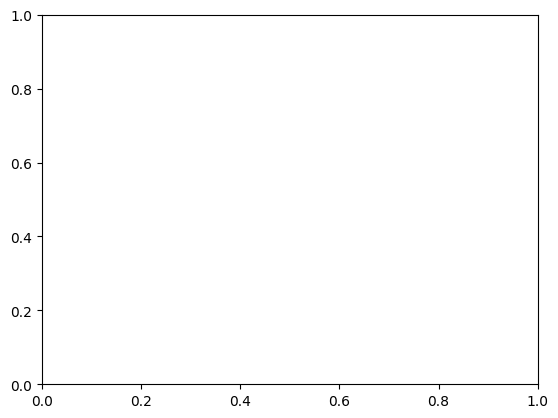

In [ ]:

fig, ax1 =plt.subplots()
sns. barplot(ax = ax1, x = 'city', y = 'jams_delay', data = merged,color = 'aquamarine')
ax2 = ax1.twinx()

sns.barplot( ax = ax2, x= 'city', y = 'city_gdp_capita', data = merged, color = 'pink')
ax1.tick_params(axis= 'x', rotation= 90)
plt.show()




**Tip:** Antes del `plt.show()` agrega el código `plt.xticks(rotation=90)` para rotar las etiquetas del eje X en 90 grados.

In [ ]:
fig, ax1 =plt.subplots()
x = np.arange(len(merged['city']))
width = 0.4
ax1.bar(x - width / 2, merged['jams_delay'], width, color='aquamarine' )
ax1.set_xticks(x)
ax1.set_xticklabels(merged['city'])
ax2 = ax1.twinx()
ax2.bar(x + width / 2, merged['city_gdp_capita'], width, color='salmon')
ax1.tick_params(axis= 'x', rotation= 90)
plt.show()


### 🧠 **Reflexiona**
Excelente trabajo llegando a esta etapa del análisis. Antes de avanzar, revisa tus gráficos, tómate un momento para pensar:

* ¿Las ciudades con mayor PIB per cápita también presentan más congestión?

* ¿O sucede lo contrario, o no existe una relación clara?

Escribe tus comentarios:


---

## 🧩Paso 7: Exportar y documentar resultados

En esta etapa final consolidarás todo tu trabajo: guardarás el dataset limpio y crearás un resumen que documente los resultados del proyecto.

### 7.1 Guardar dataset final

**🎯Objetivo:**
Generar un CSV limpio, reproducible y con columnas relevantes para análisis posterior.

**Instrucciones**

- Exporta el DataFrame `merged` con el nombre: `ladb_mobility_economy_2024_clean.csv`
- Usa `index=False` para no incluir el índice.


In [ ]:
# Exporta el dataset final como CSV
merged.to_csv("ladb_mobility_economy_2024_clean.csv", index=False)

Para poder ver o descargar el archivo generado:   
En el menú lateral que esta a la izquierda, ve hasta la parte de abajo, a la sección de **Exportar dataset** para más información.

<div class="alert alert-block alert-success">
<b>Comentario de la revisora Iteración #1</b> <a class="tocSkip"></a>

Bien hecho! Creaste el archivo final como CSV.


---

## ✅ Entregables

1. **Notebook `.ipynb`** con todas las celdas (código + comentarios).
2. **CSV final**: `ladb_mobility_economy_2024_clean.csv`.
3. **Resumen ejecutivo breve** en Markdown (3–5 párrafos).



---

# 🧾 Resumen ejecutivo (plantilla)

> Completa este resumen al finalizar el análisis. Mantén 3–5 párrafos cortos, claros y accionables.

**Contexto & objetivo:**  
- Responde la pregunta central del análisis: ¿qué relación existe entre la movilidad urbana (congestión, tiempos de viaje) y la productividad económica (PIB per cápita)?
- Explica brevemente las variables clave utilizadas y su relevancia para la toma de decisiones.

**Cobertura de datos:**  
- Especifica los años analizados, número de ciudades y países incluidos.

**Metodología (alto nivel):**  
- Describe los procesos principales: limpieza de datos (formatos, estandarización de columnas).
- Explica la agregación por ciudad–año y el uso de una unión INNER para integrar tráfico y economía.
- Menciona las validaciones visuales empleadas (distribuciones, outliers, tendencias generales).

**Hallazgos iniciales:**  
- Resume los patrones más importantes entre índices de tráfico y PIB per cápita.
- Destaca anomalías u outliers que podrían requerir revisión adicional o un análisis más profundo.

**Recomendaciones**  
Aterriza los hallazgos en acciones: ciudades prioritarias, necesidad de validar fuentes, requerimiento de análisis adicionales, o propuestas de inversión.

- ¿Qué ciudad : Bogotá, Lima o Buenos Aires o alguna otra en particular, muestra la mayor correlación significativa entre altos niveles de congestión vehicular y bajos indicadores de productividad económica, sugiriendo ser una ciudad prioritaria para inversión en infraestructura de transporte?


In [ ]:
INFORME EJECUTIVO: Movilidad Urbana y Productividad Económica
1. Contexto y Objetivo
El presente análisis responde a la relación central entre movilidad urbana y productividad económica: existe una correlación negativa directa:
a mayor tiempo perdido por congestión vehicular, menor es el PIB per cápita de la ciudad. Las variables utilizadas —jams_delay (minutos perdidos por congestión)
y city_gdp_capita (PIB per cápita)— permiten cuantificar el impacto económico de la movilidad deficiente y orientar la asignación de recursos de inversión.
2. Cobertura y Metodología
Período: Año 2024
Ciudades evaluadas: Bogotá, Lima y Buenos Aires, con referencias comparativas regionales
Se realizó estandarización, limpieza de formatos y unión INNER entre registros de tráfico y económicos, agrupados por ciudad–año.
Se validó la información mediante: diagrama de caja para detección de valores atípicos en tiempos de retraso, histograma para la distribución del PIB per cápita
y gráfico de barras para comparación directa por ciudad.
3. Hallazgos Principales
El promedio de tiempo perdido por congestión es de 629,52 minutos anuales por conductor; se identificaron valores atípicos que revelan ciudades con retrasos muy
superiores a la media.
La mayor concentración de ciudades presenta un PIB per cápita entre 10.000 y 15.000 unidades monetarias.
Ciudad prioritaria: Lima muestra la correlación negativa más marcada: registra los niveles de congestión más elevados y, simultáneamente, el PIB per cápita más
bajo del grupo. Bogotá y Buenos Aires, aunque también sufren congestión, mantienen indicadores de productividad sensiblemente superiores.
4. Recomendaciones
Inversión inmediata en Lima: Asignar recursos prioritarios para ampliación de transporte público masivo, mejoras viales y gestión de tráfico.
Validación de datos: Revisar los valores atípicos detectados para descartar errores de registro y confirmar su consistencia.
Análisis de causalidad: Ampliar el estudio a series históricas 2022–2025 para verificar si la relación se mantiene en el tiempo.
Planificación integrada: Diseñar intervenciones que combinen infraestructura con ordenamiento territorial, reduciendo distancias entre zonas residenciales y laborales.